# 影片前處理：SigLIP 2 Video Encoder
流程：影片 → 鏡頭切分 → 4 fps 擷取影格 → SigLIP 2 逐格編碼 → pooling → 每支影片一個向量
輸出：`features/video/{DATA_MODE}_{MODEL_TAG}.pt`，主 notebook 的 2.3 Video Encoder 直接讀取

**為什麼另開一本 notebook？**
1. 影片解碼與編碼最花時間，只需跑一次
2. 需要的套件（PySceneDetect、OpenCV）跟主模型無關
3. 快取以 `media_id` 命名，pilot 算過的影片，full 模式可以直接沿用

**和 MM-AU（§6.1）的對照**

| 步驟 | MM-AU | 本專案 |
|---|---|---|
| 鏡頭切分 | PySceneDetect | 同，ContentDetector |
| 影格擷取 | 4 fps | 同，每支上限 480 格 |
| 影格編碼 | CLIP ViT-B/32 | SigLIP 2 base-patch16-**naflex** |
| 影格 → 鏡頭 | average pool | 同 |
| 鏡頭 → 影片 | 無（鏡頭序列直接進 LSTM / Transformer） | **固定 32 格再 max-pool**（理由見第 10 節） |

# 0. 匯入與參數

| 參數 | 設定 | 為什麼 |
|---|---|---|
| `SAMPLE_FPS` | 4 | 照 MM-AU §6.1 |
| `MAX_FRAMES` | 480 | = 120 秒 × 4 fps。抽樣的 50 支影片最長 120 秒、75 百分位 70 秒。原本設 360，超過 90 秒的影片會改成均勻抽格，取樣密度就跟其他影片不一樣；改成 480 後，全部影片都維持 4 fps |
| `SIGLIP_MODEL` | naflex | 96% 是 9:16 直式。正方形輸入的版本，不是把畫面壓扁，就是把上下的字卡裁掉。NaFlex 保留原始長寬比，SigLIP 2 論文指出它在 OCR、文件類 benchmark 多半比較好 |
| `MAX_PATCHES` | 256 | 9:16 約 12×21 個 patch（約 192×336 px）。576 能看清更多畫面文字，但運算量約 2.5 倍，留作 ablation |
| `RESIZE_LONG` | 512 | 主流解析度 720×1280，讀進來先縮小，省記憶體；NaFlex 實際只用到約 336 px，不損失資訊 |
| `SCENE_THRESHOLD` / `MIN_SCENE_SEC` | 27 / 0.5 秒 | MM-AU 沒寫，用 PySceneDetect 預設值。Reels 剪接快，限制最短 0.5 秒，確保每個鏡頭至少抽得到一格 |
| `FIXED_K` | 32 | 每支影片均勻取 32 格再 max，消除「格數越多、最大值越高」的偏誤（見第 10 節） |
| `MAX_SHOTS` | 35 | 照 MM-AU；只影響存下的鏡頭序列，不影響 pooling 向量 |
| `RUN_SCENE_DETECT` | True | pilot 保留鏡頭資訊，供 SPoD 整合時測試 attention pooling；若無效，full 資料集改 False |

> 論文沒有寫、自己決定的參數，在程式碼註解標了「← MM-AU 未給」或「← 自訂」

In [53]:
# 若尚未安裝：pip install "scenedetect[opencv]" "transformers>=4.49"
import warnings, random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
from transformers import AutoModel, AutoProcessor
from scenedetect import open_video, SceneManager, ContentDetector
import matplotlib.pyplot as plt

In [ ]:
# ── 資料模式 ──
DATA_MODE = "pilot"        # "pilot" / "full"

ROOT      = Path("/home/yingtzudai/Multimodal_SPoD_Video")
SPLIT_CSV = {"pilot": ROOT / "data/split/pilot_posts.csv",
             "full":  ROOT / "data/split/post_split.csv"}[DATA_MODE]
DATA_ROOT = Path("/home/ftp_246/data_5/多模態2026_ig_top200")
VIDEO_DIR = DATA_ROOT / "Video_data_fullest/ig_vedios"          # {username}/{stem}.mp4
FEAT_DIR  = ROOT / "features"

SEED   = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE  = torch.float16 if device.type == "cuda" else torch.float32
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ── 鏡頭切分（MM-AU：PySceneDetect）──
RUN_SCENE_DETECT = True    # full 資料集若 attention pooling 未證實有用，改 False，省下一次完整解碼
SCENE_THRESHOLD = 27.0     # ContentDetector 預設值 ← MM-AU 未給
MIN_SCENE_SEC   = 0.5      # 最短鏡頭長度          ← MM-AU 未給

# ── 影格擷取（MM-AU：4 fps）──
SAMPLE_FPS  = 4
MAX_FRAMES  = 480          # 最多480格，超過約120秒則均勻取樣(因Pilot video最常者只有約120秒)
RESIZE_LONG = 512          # 讀進來先把長邊縮到 512，省記憶體（NaFlex 實際只用到約 336px）

# ── SigLIP 2 ──
SIGLIP_MODEL = "google/siglip2-base-patch16-naflex"   # ablation："google/siglip2-base-patch16-224"
MAX_PATCHES  = 256 # NaFlex 序列長度；MAX_PATCHES = 256 是每張影像的 patch 數量預算。對 9:16 影像，理想化的網格可能接近 12×21，但實際配置應以 processor 的輸出為準。
FRAME_BATCH  = 32
PROC_KW = {"max_num_patches": MAX_PATCHES} if "naflex" in SIGLIP_MODEL else {}

# ── Pooling / 序列 ──
FIXED_K   = 32             # 每支影片均勻取 K 格再 max（消除格數造成的極值效應）
POOLS     = ["max_k", "mean_shot", "mean_frame", "max"]   # 第一個是預設，其餘為 ablation
MAX_SHOTS = 35

# ── 存檔 ──
MODEL_TAG = (SIGLIP_MODEL.split("/")[-1]
             + (f"_p{MAX_PATCHES}" if PROC_KW else "") + f"_fps{SAMPLE_FPS}")
CACHE_DIR = FEAT_DIR / "video" / "cache" / MODEL_TAG   # 每支影片一個檔，pilot / full 共用
OUT_PT    = FEAT_DIR / "video" / f"{DATA_MODE}_{MODEL_TAG}.pt"
SAVE_FRAME_EMB = True      # 保留逐格 embedding，之後換 pooling 不用重算
RECOMPUTE      = False
CACHE_DIR.mkdir(parents=True, exist_ok=True)
print(device, "|", MODEL_TAG)

cuda | siglip2-base-patch16-naflex_p256_fps4


# 1. 貼文清單與影片路徑

In [55]:
posts = pd.read_csv(SPLIT_CSV, dtype={"media_id": str, "stem": str})
posts["media_id"]   = posts["media_id"].str.strip()
posts["video_path"] = [VIDEO_DIR / u / f"{s}.mp4" for u, s in zip(posts["username"], posts["stem"])]
posts["has_video"]  = posts["video_path"].map(Path.exists)

print(posts.shape, "| 找得到影片的比例：", posts["has_video"].mean().round(3))
print(posts.loc[~posts["has_video"], ["username", "stem"]].head())

(299, 9) | 找得到影片的比例： 1.0
Empty DataFrame
Columns: [username, stem]
Index: []


In [ ]:
assert posts["media_id"].notna().all(), "有缺少 media_id 的貼文"
assert posts["media_id"].is_unique, "media_id 有重複，請先檢查"

assert posts["username"].notna().all()
assert posts["stem"].notna().all()

# 2. 影片格式檢查
只讀檔頭、不解碼，很快。用來決定 `MAX_FRAMES`、`RESIZE_LONG`。

**抽樣結果（n = 50）**
- fps：23.98–30，大多是 30
- 解析度：主流 720×1280，最小 360×640
- 長度：中位數 44.7 秒，75 百分位 70.5 秒，最長 120.3 秒
- 直式比例 96%；4 fps 下平均每支 198 格

**為什麼不排除 outlier（橫式、極短、很長的影片）？**
1. **避免選擇偏誤**：SPoD 要對所有貼文排序，實際使用時一定會遇到這些影片
2. **格式本身可能是訊號**：橫式可能是品牌提供的廣告素材；長度也跟業配有關（業配中位數 59.9 秒，非業配 37.1 秒）
3. **流程本身能處理**：NaFlex 不會讓橫式變形；最短的影片也有約 35 格；pooling 後每支都是同樣維度的向量

真正排除的只有技術上壞掉的檔案，而且不刪資料，只標成 `video_ok = False`，當作「缺少影片模態」。

In [56]:
def probe(path):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        return None
    fps = cap.get(cv2.CAP_PROP_FPS)
    n   = cap.get(cv2.CAP_PROP_FRAME_COUNT)
    w, h = cap.get(cv2.CAP_PROP_FRAME_WIDTH), cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
    cap.release()
    return {"fps": fps, "n_frames": n, "width": w, "height": h,
            "duration": n / fps if fps else np.nan}

sample = posts[posts["has_video"]].sample(min(50, posts["has_video"].sum()), random_state=SEED)
info = pd.DataFrame([probe(p) or {} for p in sample["video_path"]])
print(info.describe().T.round(2))
print("直式比例：", (info["height"] > info["width"]).mean().round(3))
print("4 fps 下平均每支影格數：", (info["duration"] * SAMPLE_FPS).mean().round(0))

          count     mean     std     min      25%      50%      75%      max
fps        50.0    29.76    1.19   23.98    30.00    30.00    30.00    30.00
n_frames   50.0  1476.32  886.87  261.00   725.25  1301.00  2115.50  3610.00
width      50.0   716.80  108.07  360.00   720.00   720.00   720.00  1280.00
height     50.0  1232.00  164.83  640.00  1280.00  1280.00  1280.00  1280.00
duration   50.0    49.45   29.44    8.70    24.18    44.66    70.52   120.33
直式比例： 0.96
4 fps 下平均每支影格數： 198.0


In [ ]:
# 全部影片都讀一次檔頭，結果併回 posts
info_all = pd.DataFrame([probe(p) if ok else {} for p, ok in zip(posts["video_path"], posts["has_video"])],
                        index=posts.index)
posts = posts.drop(columns=info_all.columns, errors="ignore").join(info_all)   # 重跑時先移除舊欄位
posts["orient"] = np.where(posts["height"] > posts["width"], "portrait",
                  np.where(posts["height"] < posts["width"], "landscape", "square"))
posts["dur_bin"] = pd.cut(posts["duration"], [0, 15, 30, 60, 90, np.inf],
                          labels=["<15s", "15-30s", "30-60s", "60-90s", ">90s"])

print("讀不到 / 長度 < 1 秒：", int(((posts["duration"] < 1) | posts["duration"].isna()).sum()), "支")
print("\n各方向的業配比例")
print(posts.groupby("orient")["label"].agg(["mean", "count"]).round(3))
print("\n各長度區間的業配比例")
print(posts.groupby("dur_bin", observed=True)["label"].agg(["mean", "count"]).round(3))
print("\n超過 MAX_FRAMES 上限、會改為均勻抽格的比例：",
      (posts["duration"] * SAMPLE_FPS > MAX_FRAMES).mean().round(3))

讀不到 / 長度 < 1 秒： 0 支

各方向的業配比例
            mean  count
orient                 
landscape  0.600      5
portrait   0.454    293
square     0.000      1

各長度區間的業配比例
          mean  count
dur_bin              
<15s     0.211     38
15-30s   0.227     44
30-60s   0.419    124
60-90s   0.750     64
>90s     0.621     29

超過 MAX_FRAMES 上限、會改為均勻抽格的比例： 0.047


上面結果顯示，影片越長，業配的比例越高，也因此後面要留意影片長度問題，避免因此洩露label

**全部 299 支的結果**
- 讀不到或長度不足 1 秒：0 支
- 業配比例隨長度上升：<15 秒 21%、30–60 秒 42%、60–90 秒 75% → 長度是很強的訊號，第 10 節要處理
- 橫式 5 支、正方形 1 支：樣本太少，不做結論
- 4.7% 超過 2 分鐘，改為均勻抽格

# 3. 鏡頭切分（PySceneDetect）
- 用 `ContentDetector`：比較相鄰畫面的色彩差異，差異超過門檻就算換鏡頭
- 一鏡到底的影片 → 整支當成一個鏡頭

**檢查結果（pilot）**：鏡頭數中位數 13、最多 122；每秒最多 1.19 個鏡頭，沒有發現閃光或字卡被大量誤判，門檻不用調整。

In [ ]:
def detect_shots(path, fps, duration):
    video = open_video(str(path))
    sm = SceneManager()
    sm.add_detector(ContentDetector(threshold=SCENE_THRESHOLD,
                                    min_scene_len=max(1, int(MIN_SCENE_SEC * fps))))
    sm.detect_scenes(video, show_progress=False)
    scenes = sm.get_scene_list(start_in_scene=True)
    shots = [(s.seconds, e.seconds) for s, e in scenes]
    return shots or [(0.0, duration)]          # 一鏡到底 → 整支當一個鏡頭

# 抽 3 支看切得合不合理（可對照影片手動檢查）
for p in sample["video_path"].head(3):
    i = probe(p)
    s = detect_shots(p, i["fps"], i["duration"])
    print(p.name, f"{i['duration']:.1f}s →", len(s), "個鏡頭", [round(a, 1) for a, _ in s][:10])

/tmp/ipykernel_412609/1479378777.py:8: DeprecationWarning: get_seconds() is deprecated, use the `seconds` property instead.
  shots = [(s.get_seconds(), e.get_seconds()) for s, e in scenes]


thetiffanychen-20251228211256-1216903180549089.mp4 94.6s → 50 個鏡頭 [0.0, 5.4, 6.6, 7.3, 7.9, 8.6, 13.4, 15.4, 16.9, 18.7]
1_shiuan_0-20250908004431-1635094370996640.mp4 51.7s → 13 個鏡頭 [0.0, 10.3, 16.4, 18.1, 34.6, 35.9, 38.6, 44.3, 46.5, 47.7]
zoebitalk-20250630230332-1492024018951094.mp4 13.8s → 11 個鏡頭 [0.0, 5.6, 6.4, 7.1, 7.7, 8.5, 9.4, 10.1, 10.7, 11.8]


# 4. 影格擷取（4 fps）
- 依序讀每一格，只解碼需要的那幾格（`grab` / `retrieve`），比用 `CAP_PROP_POS_MSEC` 跳著讀更準
- 用影片自己的 fps 換算時間，23.98 fps 這種非整數也能算對
- 超過 480 格（約 2 分鐘）才改成均勻抽格

In [ ]:
def sample_frames(path, fps, n_frames):
    if not np.isfinite(fps) or fps <= 0:
        raise ValueError(f"影片 FPS 無效：{fps}")

    if not np.isfinite(n_frames) or n_frames < 1:
        raise ValueError(f"影格數無效：{n_frames}")
    
    duration = n_frames / fps
    times = np.arange(0, duration, 1 / SAMPLE_FPS)
    if len(times) > MAX_FRAMES:
        times = np.linspace(0, duration, MAX_FRAMES, endpoint=False)
    targets = set(np.minimum(np.round(times * fps).astype(int), int(n_frames) - 1).tolist())
    last = max(targets)

    cap, frames, ts, i = cv2.VideoCapture(str(path)), [], [], 0
    while i <= last and cap.grab():
        if i in targets:
            ok, img = cap.retrieve()
            if ok:
                h, w = img.shape[:2]
                s = RESIZE_LONG / max(h, w)
                if s < 1:
                    img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
                frames.append(Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)))
                ts.append(i / fps)
        i += 1
    cap.release()
    return frames, np.array(ts)

# 5. SigLIP 2 影格 embedding
- `get_image_features` 拿到的是 MAP head（attention pooling）的輸出。SigLIP 沒有 [CLS]，這就是整張圖的代表向量，base 版 768 維
- 每格先做 **L2 normalize**：SigLIP 是在 cosine 空間訓練的，先 normalize 再平均或取最大，比較合理
- 對照組：`google/siglip2-base-patch16-224`（正方形輸入）。SigLIP 2 論文指出，B 尺寸在自然影像上標準版比 NaFlex 好，所以留作 ablation

In [60]:
processor = AutoProcessor.from_pretrained(SIGLIP_MODEL)
siglip = AutoModel.from_pretrained(SIGLIP_MODEL, torch_dtype=DTYPE).to(device).eval()

@torch.no_grad()
def encode_frames(frames):
    out = []
    for i in range(0, len(frames), FRAME_BATCH):
        inputs = processor(images=frames[i:i + FRAME_BATCH], return_tensors="pt", **PROC_KW).to(device)
        inputs["pixel_values"] = inputs["pixel_values"].to(DTYPE)
        e = siglip.get_image_features(**inputs)
        if not torch.is_tensor(e):              # 新版 transformers 可能回傳 output 物件
            e = e.pooler_output
        out.append(F.normalize(e.float(), dim=-1).cpu())
    return torch.cat(out)                       # (影格數, d)；base = 768

EMB_DIM = siglip.config.vision_config.hidden_size
print("EMB_DIM:", EMB_DIM)

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

EMB_DIM: 768


# 6. Pooling：影格 → 鏡頭 → 影片

| 名稱 | 做法 | 角色 |
|---|---|---|
| `max_k` | 均勻取 32 格，每一維取最大值 | **預設** |
| `mean_shot` | 先平均成鏡頭，再平均所有鏡頭（每個鏡頭等權） | ablation |
| `mean_frame` | 所有影格直接平均（等於依時長加權） | ablation |
| `max` | 所有影格取最大值（SPoD 的 image max-pool） | ablation：會混進影片長度 |
| `shots` | 鏡頭序列，最多 35 個 | 之後做 attention pooling 用 |

選擇過程見第 10 節。

In [61]:
def pool_video(frame_emb, ts, shots):
    shot_embs = []
    for s, e in shots:
        m = torch.from_numpy((ts >= s) & (ts < e))
        if m.any():                             # 太短、沒抽到影格的鏡頭跳過
            shot_embs.append(frame_emb[m].mean(0))
    S = torch.stack(shot_embs) if shot_embs else frame_emb.mean(0, keepdim=True)
    k_idx = torch.linspace(0, len(frame_emb) - 1, FIXED_K).round().long()
    return {
        "shots":      S,
        "max_k":      frame_emb[k_idx].max(0).values,   # 預設：固定 K 格再 max
        "mean_shot":  S.mean(0),
        "mean_frame": frame_emb.mean(0),
        "max":        frame_emb.max(0).values,          # ablation：受格數影響
    }

# 7. 批次執行（可中斷續跑）
- 每支影片存成 `cache/{MODEL_TAG}/{media_id}.pt`，已經存在就跳過，中斷後重跑會接著做
- 逐格 embedding 也一起存（`SAVE_FRAME_EMB`）：之後換 pooling 方法不用重新編碼，第 10 節的固定格數檢驗就是靠這個
- 單支出錯不會讓整批停下來，狀態記錄在 `*_log.csv`
- 相鄰影格平均 cosine > 0.99 → 標 `static`（例如單張圖片做成的影片），之後再決定要不要當成缺模態

**Pilot 結果**：299 / 299 支成功編碼

In [ ]:
def process_video(row):
    out = CACHE_DIR / f"{row.media_id}.pt"
    if out.exists() and not RECOMPUTE:
        return "cached"
    if not Path(row.video_path).exists():
        return "missing"
    info = probe(row.video_path)
    if info is None or not info["fps"] or info["n_frames"] < 1:
        return "unreadable"
    shots = (detect_shots(row.video_path, info["fps"], info["duration"]) if RUN_SCENE_DETECT
             else [(0.0, info["duration"])])        # 關掉時整支當一個鏡頭
    frames, ts = sample_frames(row.video_path, info["fps"], info["n_frames"])
    if not frames:
        return "no_frames"
    emb = encode_frames(frames)
    # 幾乎靜止（相鄰影格平均 cosine > 0.99，例如把單張圖片做成影片）→ 一樣存檔，但做標記
    static = len(emb) > 1 and float((emb[1:] * emb[:-1]).sum(-1).mean()) > 0.99
    pooled = pool_video(emb, ts, shots)
    torch.save({"media_id": row.media_id, "model": SIGLIP_MODEL, "info": info,
                "ts": ts, "shots_sec": shots, "static": static,
                "frame_emb": emb.half() if SAVE_FRAME_EMB else None,
                **{k: v.half() for k, v in pooled.items()}}, out)
    return "ok"

log = []
for row in tqdm(posts.itertuples(), total=len(posts), desc="video"):
    try:
        status = process_video(row)
    except Exception as ex:
        status = f"error: {type(ex).__name__}: {ex}"
    log.append((row.media_id, status))

log = pd.DataFrame(log, columns=["media_id", "status"])
print(log["status"].str.split(":").str[0].value_counts())
log.to_csv(CACHE_DIR.parent / f"{DATA_MODE}_{MODEL_TAG}_log.csv", index=False)

video:   0%|          | 0/299 [00:00<?, ?it/s]

status
cached    299
Name: count, dtype: int64


# 8. 彙整存檔
輸出格式比照 text embedding：用 `media_id` 對齊，主 notebook 依 `posts` 的順序取出。

| 欄位 | 內容 |
|---|---|
| `X_V[pool]` | (貼文數, 768)，各種 pooling 的影片向量 |
| `shots`, `shot_mask` | (貼文數, 35, 768) 鏡頭序列與 mask |
| `video_ok` | 哪些貼文有成功編碼的影片，aspect attention 處理缺模態時用 |
| `config` | 產生這份檔案的所有參數 |

11.7% 的影片超過 35 個鏡頭。`shots` 會從全部鏡頭中**均勻挑 35 個**，保留先後順序並涵蓋整支影片（只留前 35 個會系統性丟掉結尾，而結尾常是產品效果或購買資訊）。`shot_time` 記錄每個鏡頭的起訖秒數，之後做 attention pooling 時可以指出權重最高的鏡頭在第幾秒。pooling 向量是用全部影格或鏡頭算的，不受這個上限影響。

| 欄位 | 內容 |
|---|---|
| `shot_time` | (貼文數, 35, 2)，每個保留鏡頭的起訖秒數 |
| `static` | 近乎靜止的影片（相鄰影格平均 cosine > 0.99） |

In [ ]:
N = len(posts)

X_V = {p: torch.zeros(N, EMB_DIM) for p in POOLS}
shots_pad = torch.zeros(N, MAX_SHOTS, EMB_DIM, dtype=torch.float16)
shot_mask = torch.zeros(N, MAX_SHOTS, dtype=torch.bool)
shot_time = torch.full((N, MAX_SHOTS, 2), float("nan"))
video_ok = torch.zeros(N, dtype=torch.bool)
static_flag = torch.zeros(N, dtype=torch.bool)
n_shots = np.zeros(N, dtype=int)

for i, m in enumerate(posts["media_id"]):
    f = CACHE_DIR / f"{m}.pt"

    if not f.exists():
        continue

    c = torch.load(f, map_location="cpu", weights_only=False)

    # 1. 確認快取屬於目前的貼文與模型
    if str(c.get("media_id")) != str(m):
        raise ValueError(f"media_id 不一致：{m}")

    if c.get("model") != SIGLIP_MODEL:
        raise ValueError(f"模型不一致：{m}")

    # 2. 儲存不同 pooling 的影片向量
    for p in POOLS:
        if p in c:
            X_V[p][i] = c[p].float()

        elif p == "max_k":
            fe = c.get("frame_emb")
            if fe is None:
                raise ValueError(f"{m} 缺少 frame_emb")

            fe = fe.float()
            idx = torch.linspace(
                0, len(fe) - 1, FIXED_K
            ).round().long()

            X_V[p][i] = fe[idx].max(0).values

        else:
            raise ValueError(f"{m} 缺少 pooling：{p}")

    # 3. 儲存鏡頭序列
    # 注意：必須放在 for p in POOLS 之外
    S = c["shots"].float()
    ts = np.asarray(c["ts"])

    sec = [
        (s, e)
        for s, e in c["shots_sec"]
        if ((ts >= s) & (ts < e)).any()
    ]

    if len(sec) != len(S):
        raise ValueError(f"{m} 鏡頭數與時間資訊不一致")

    keep = np.arange(len(S))

    if len(S) > MAX_SHOTS:
        keep = np.linspace(
            0, len(S) - 1, MAX_SHOTS
        ).round().astype(int)

    shots_pad[i, :len(keep)] = S[keep]
    shot_mask[i, :len(keep)] = True
    shot_time[i, :len(keep)] = torch.tensor(
        [sec[k] for k in keep], dtype=torch.float32
    )

    n_shots[i] = len(S)

    # 補算 static（舊快取沒有存這個欄位）
    fe_s = c["frame_emb"].float()
    static_flag[i] = bool(c.get("static", len(fe_s) > 1 and
                          float((fe_s[1:] * fe_s[:-1]).sum(-1).mean()) > 0.99))
    video_ok[i] = True

# 4. 檢查輸出形狀與有效位置
assert int(shot_mask.sum(1)[video_ok].min()) > 0
assert torch.isfinite(X_V["max_k"][video_ok]).all()

# 5. 儲存結果
torch.save({
    "media_id": posts["media_id"].tolist(),
    "X_V": X_V,
    "shots": shots_pad,
    "shot_mask": shot_mask,
    "shot_time": shot_time,
    "video_ok": video_ok,
    "static": static_flag,
    "config": {
        "model": SIGLIP_MODEL,
        "max_patches": MAX_PATCHES,
        "fps": SAMPLE_FPS,
        "max_frames": MAX_FRAMES,
        "resize_long": RESIZE_LONG,
        "scene_threshold": SCENE_THRESHOLD,
        "min_scene_sec": MIN_SCENE_SEC,
        "max_shots": MAX_SHOTS,
        "fixed_k": FIXED_K,
        "shot_sampling": "uniform",
        "run_scene_detect": RUN_SCENE_DETECT
    }
}, OUT_PT)

print("成功編碼：", int(video_ok.sum()), "/", N)
print("有效鏡頭數：", int(shot_mask.sum()))
print("近乎靜止的影片：", int(static_flag.sum()), "支")


## 8.1 檢查彙整檔是否為新版

In [ ]:
saved = torch.load(OUT_PT, weights_only=False)
print("檔案欄位：", sorted(saved.keys()))
print("pooling：", sorted(saved["X_V"].keys()))
print("有 shot_time（新版）：", "shot_time" in saved)
print("有鏡頭資料的影片：", saved["shot_mask"].any(1).sum().item(), "/", len(saved["media_id"]))

# 9. 快速檢查：影片向量有沒有業配訊號
用 logistic regression 做 linear probe，5-fold 交叉驗證。

**為什麼要按網紅分組（StratifiedGroupKFold）？**
同一位網紅的影片風格很像。如果同一位網紅的影片同時出現在訓練和測試裡，模型可能只是認出「這是常接業配的某某某」，分數會被高估。分組後，測試的網紅一定是模型沒看過的。

隨機基準 AP = 業配比例 = 136 / 299 ≈ 0.455

In [64]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import average_precision_score

ok = video_ok.numpy()
yv, g = posts["label"].values[ok], posts["username"].values[ok]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
print("隨機基準 AP ≈", yv.mean().round(3))
for p in POOLS:
    prob = cross_val_predict(LogisticRegression(max_iter=2000), X_V[p][ok].numpy(), yv,
                             cv=cv, groups=g, method="predict_proba")[:, 1]
    print(f"{p:10s} AP = {average_precision_score(yv, prob):.3f}")

隨機基準 AP ≈ 0.455
max_k      AP = 0.774
mean_shot  AP = 0.693
mean_frame AP = 0.686
max        AP = 0.775


# 10. 穩健性檢查：pooling 方法怎麼選出來的
每個設定用 10 個隨機種子重複，報告 AP 的平均 ± 標準差。

**第一、二輪：`max` 最好，但跟長度高度相關**
- `max` 0.785，遠高於 `mean_shot` 0.651、`mean_frame` 0.659
- 但只用影片長度就有 0.649；業配中位數 59.9 秒、非業配 37.1 秒
- `max` 向量的整體高度和 log(長度) 相關 0.686：格數越多，最大值必然越大
- 扣除長度效應後，`max` 掉到 0.553
→ 懷疑 `max` 只是在間接記錄影片長度

**第三輪：明確給出長度後，`max` 仍然領先**
- 長度 + mean_shot 0.657、長度 + max 0.783
→ `max` 有「線性長度」以外的資訊，可能是 (a) 非線性的長度效應，或 (b) 真的有關鍵畫面

**第四輪：分開兩種解釋**
- 每支都固定抽 32 格 → 格數造成的效應消失；長度改用 spline → 任何形狀都學得到
- 非線性長度單獨只有 0.625 → 排除 (a)
- `max_32` − `mean_32` = +0.086 ± 0.025，10 次全勝 → 支持 (b)
- 給了非線性長度後，`max_32` 仍比 `mean_32` 多 0.075，10 次全勝

**決定**：預設用 `max_k`（K = 32）。保留 SPoD「任何一張畫面出現產品就算」的 max-pool 邏輯，又不受影片長度影響。

**影片對文字有沒有幫助？**
- 跟「text + 長度」相比，加上 `max_32` 多 0.043、加上 `mean_32` 多 0.036，都是 10 次全勝 → 值得整合
- 有文字時，max 和 mean 的差距縮小（0.849 對 0.841），推測關鍵畫面的資訊和 caption 有部分重疊
- 長度單獨當 feature 只多約 0.006 → 不另設 aspect，之後當作 graph 的 post node feature

**限制**
- linear probe 不等於最終的 SPoD 模型
- 10 次重複用的是同一批資料，「10 次全勝」不是正式的顯著性檢定
- K = 32 是暫定值，正式實驗比較 16 / 32 / 64
- 業配和長度的關係要在 full 資料上再確認一次

## 10.1 重複交叉驗證，並納入影片長度與文字作對照
每個 seed 都換一種切法、重跑 10 次，看平均和標準差。另外加入幾組對照：只用影片長度、把長度效應從 max 扣掉、只用文字，以及文字加影片

In [65]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 影片長度與鏡頭數（從快取讀）
dur = np.array([torch.load(CACHE_DIR / f"{m}.pt", weights_only=False)["info"]["duration"]
                for m in posts["media_id"]])
ok  = video_ok.numpy()
yv, g = posts["label"].values[ok], posts["username"].values[ok]
log_dur = np.log(dur[ok])[:, None]

# Text embedding（與主 notebook 同一份）
t = torch.load(FEAT_DIR / "text" / "pilot_ckiplab_bert-base-chinese_masked.pt", weights_only=False)
tpos = {m: i for i, m in enumerate(t["media_id"])}
X_T = t["X_T"][[tpos[m] for m in posts["media_id"]]].numpy()[ok]

# 把 max 向量中可由「影片長度」線性解釋的部分扣掉（不使用 label，不會洩漏）
def residualize(X, z):
    Z = np.c_[np.ones(len(z)), z]
    return X - Z @ np.linalg.lstsq(Z, X, rcond=None)[0]

V = {p: X_V[p][ok].numpy() for p in POOLS}
candidates = {
    "長度 only":          np.c_[log_dur, np.log(n_shots[ok])[:, None]],
    "mean_shot":          V["mean_shot"],
    "mean_frame":         V["mean_frame"],
    "max":                V["max"],
    "max（扣除長度效應）": residualize(V["max"], log_dur),
    "text":               X_T,
    "text + mean_shot":   np.c_[X_T, V["mean_shot"]],
    "text + max":         np.c_[X_T, V["max"]],
}

def grouped_ap(X, seeds=range(10)):
    aps = []
    for s in seeds:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
        prob = cross_val_predict(clf, X, yv, cv=cv, groups=g, method="predict_proba")[:, 1]
        aps.append(average_precision_score(yv, prob))
    return np.mean(aps), np.std(aps)

print(f"隨機基準 AP ≈ {yv.mean():.3f}　｜　網紅數：{len(np.unique(g))}")
res = pd.DataFrame({k: grouped_ap(X) for k, X in candidates.items()}, index=["AP_mean", "AP_sd"]).T
print(res.round(3))

隨機基準 AP ≈ 0.455　｜　網紅數：99
                  AP_mean  AP_sd
長度 only             0.649  0.015
mean_shot           0.651  0.018
mean_frame          0.659  0.021
max                 0.785  0.017
max（扣除長度效應）         0.553  0.016
text                0.800  0.015
text + mean_shot    0.833  0.014
text + max          0.857  0.011


## 10.2 max與影片長度的關聯

In [66]:
mx_level = V["max"].mean(1)          # max 向量的整體高度
print("max 向量平均值 vs log(長度) 相關：", np.corrcoef(mx_level, log_dur[:, 0])[0, 1].round(3))
print("業配 / 非業配的影片長度中位數（秒）：",
      np.median(dur[ok][yv == 1]).round(1), "/", np.median(dur[ok][yv == 0]).round(1))

max 向量平均值 vs log(長度) 相關： 0.686
業配 / 非業配的影片長度中位數（秒）： 59.9 / 37.1


## 10.3 鏡頭數異常的影片

In [67]:
chk = posts.loc[ok, ["username", "stem", "label"]].assign(
    n_shots=n_shots[ok], duration=dur[ok].round(1))
chk["shots_per_sec"] = (chk["n_shots"] / chk["duration"]).round(2)
print(chk.sort_values("shots_per_sec", ascending=False).head(8).to_string())

           username                                            stem  label  n_shots  duration  shots_per_sec
204        japanuts        japanuts-20251228201320-2331979960639984      1       45      37.8           1.19
243        japanuts       japanuts-20251114225239-25897867413199158      1       16      15.7           1.02
123       hooleefun       hooleefun-20250727011908-1788470765402591      1       28      31.5           0.89
287          1105ya          1105ya-20250909075605-1937957040180651      0       10      11.4           0.88
275          khshu_           khshu_-20250610213234-930772389898260      1       45      53.6           0.84
0         ala780705       ala780705-20251214122010-2615877615465778      0       29      35.9           0.81
164       zoebitalk       zoebitalk-20250630230332-1492024018951094      0       11      13.8           0.80
70   ladyflavor_cui  ladyflavor_cui-20250726210517-1410621970514561      0       46      58.0           0.79


## 10.4 扣除長度後，影片內容的淨貢獻

In [68]:
L = candidates["長度 only"]
more = {
    "mean_shot（扣除長度效應）": residualize(V["mean_shot"], log_dur),   # 與 max 的同條件對照
    "長度 + mean_shot":          np.c_[L, V["mean_shot"]],
    "長度 + max":                np.c_[L, V["max"]],
    "text + 長度":               np.c_[X_T, L],
    "text + 長度 + mean_shot":   np.c_[X_T, L, V["mean_shot"]],
    "text + 長度 + max":         np.c_[X_T, L, V["max"]],
}
res2 = pd.DataFrame({k: grouped_ap(X) for k, X in more.items()}, index=["AP_mean", "AP_sd"]).T
print(res2.round(3))

                       AP_mean  AP_sd
mean_shot（扣除長度效應）        0.504  0.014
長度 + mean_shot           0.657  0.017
長度 + max                 0.783  0.017
text + 長度                0.808  0.015
text + 長度 + mean_shot    0.833  0.014
text + 長度 + max          0.856  0.011


## 10.5 固定格數pooling與非線性長度

In [69]:
from sklearn.preprocessing import SplineTransformer

# 非線性長度：log(秒數) 的 spline 展開 + log(鏡頭數)（不使用 label，不會洩漏）
L_nl = np.c_[SplineTransformer(n_knots=6, degree=3).fit_transform(log_dur),
             np.log(n_shots[ok])[:, None]]

# 固定格數 pooling：每支影片均勻取 K 格，消除「格數越多、最大值越高」的效應
K = 32
def fixed_k_pool(media_id, k=K):
    fe = torch.load(CACHE_DIR / f"{media_id}.pt", weights_only=False)["frame_emb"].float()
    sub = fe[np.linspace(0, len(fe) - 1, k).round().astype(int)]
    return sub.mean(0).numpy(), sub.max(0).values.numpy()

_p = [fixed_k_pool(m) for m in tqdm(posts["media_id"][ok], desc=f"fixed-{K}")]
mean_k = np.stack([a for a, _ in _p])
max_k  = np.stack([b for _, b in _p])
print("max_K 平均值 vs log(長度) 相關：", np.corrcoef(max_k.mean(1), log_dur[:, 0])[0, 1].round(3))

def ap_runs(X, seeds=range(10)):
    out = []
    for s in seeds:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
        prob = cross_val_predict(clf, X, yv, cv=cv, groups=g, method="predict_proba")[:, 1]
        out.append(average_precision_score(yv, prob))
    return np.array(out)

runs = {
    "長度(非線性)":           L_nl,
    "max（原本）":            V["max"],
    f"mean_{K}":              mean_k,
    f"max_{K}":               max_k,
    "長度(非線性) + max":      np.c_[L_nl, V["max"]],
    f"長度(非線性) + mean_{K}": np.c_[L_nl, mean_k],
    f"長度(非線性) + max_{K}":  np.c_[L_nl, max_k],
    "text + 長度(非線性)":     np.c_[X_T, L_nl],
    f"text + 長度(非線性) + mean_{K}": np.c_[X_T, L_nl, mean_k],
    f"text + 長度(非線性) + max_{K}":  np.c_[X_T, L_nl, max_k],
    "text + 長度(非線性) + max":       np.c_[X_T, L_nl, V["max"]],
}
R = {k: ap_runs(X) for k, X in tqdm(runs.items(), desc="CV")}
print(pd.DataFrame({k: [v.mean(), v.std()] for k, v in R.items()},
                   index=["AP_mean", "AP_sd"]).T.round(3))

# 成對比較：同樣 10 種切法下的差值
def paired(a, b):
    d = R[a] - R[b]
    return f"{a}  −  {b}:  Δ = {d.mean():+.3f} ± {d.std():.3f}｜10 次中贏 {int((d > 0).sum())} 次"

print()
for a, b in [(f"max_{K}", f"mean_{K}"),
             (f"長度(非線性) + max_{K}", "長度(非線性)"),
             (f"長度(非線性) + max_{K}", f"長度(非線性) + mean_{K}"),
             (f"text + 長度(非線性) + mean_{K}", "text + 長度(非線性)"),
             (f"text + 長度(非線性) + max_{K}", "text + 長度(非線性)")]:
    print(paired(a, b))

fixed-32:   0%|          | 0/299 [00:00<?, ?it/s]

max_K 平均值 vs log(長度) 相關： 0.504


CV:   0%|          | 0/11 [00:00<?, ?it/s]

                          AP_mean  AP_sd
長度(非線性)                     0.625  0.013
max（原本）                     0.785  0.017
mean_32                     0.655  0.021
max_32                      0.741  0.021
長度(非線性) + max               0.776  0.019
長度(非線性) + mean_32           0.659  0.027
長度(非線性) + max_32            0.734  0.020
text + 長度(非線性)              0.806  0.019
text + 長度(非線性) + mean_32    0.841  0.012
text + 長度(非線性) + max_32     0.849  0.011
text + 長度(非線性) + max        0.855  0.011

max_32  −  mean_32:  Δ = +0.086 ± 0.025｜10 次中贏 10 次
長度(非線性) + max_32  −  長度(非線性):  Δ = +0.109 ± 0.015｜10 次中贏 10 次
長度(非線性) + max_32  −  長度(非線性) + mean_32:  Δ = +0.075 ± 0.024｜10 次中贏 10 次
text + 長度(非線性) + mean_32  −  text + 長度(非線性):  Δ = +0.036 ± 0.015｜10 次中贏 10 次
text + 長度(非線性) + max_32  −  text + 長度(非線性):  Δ = +0.043 ± 0.015｜10 次中贏 10 次


## 10.6 依鏡頭取樣 (shot-aware sampling)

In [70]:
def shot_aware_idx(ts, shots, k=K):
    """每個鏡頭至少 1 格，剩下的名額依鏡頭長度分配；鏡頭數 ≥ K 時，均勻挑 K 個鏡頭各取 1 格"""
    shots = [(s, e) for s, e in shots if ((ts >= s) & (ts < e)).any()]
    if len(shots) >= k:
        pick = np.linspace(0, len(shots) - 1, k).round().astype(int)
        shots, alloc = [shots[i] for i in pick], np.ones(k, dtype=int)
    else:
        dur = np.array([e - s for s, e in shots])
        alloc = 1 + np.floor((k - len(shots)) * dur / dur.sum()).astype(int)
        alloc[np.argsort(-dur)[:k - alloc.sum()]] += 1      # 補足捨入誤差，總數剛好 K
    idx = []
    for (s, e), a in zip(shots, alloc):
        cand = np.flatnonzero((ts >= s) & (ts < e))
        idx += cand[np.linspace(0, len(cand) - 1, a).round().astype(int)].tolist()
    return np.array(idx)

def shot_aware_pool(media_id):
    c = torch.load(CACHE_DIR / f"{media_id}.pt", weights_only=False)
    fe = c["frame_emb"].float()
    return fe[shot_aware_idx(np.asarray(c["ts"]), c["shots_sec"])].max(0).values.numpy()

max_sa = np.stack([shot_aware_pool(m) for m in tqdm(posts["media_id"][ok], desc="shot-aware")])
R[f"max_{K}_shot"] = ap_runs(max_sa)
R[f"text + 長度(非線性) + max_{K}_shot"] = ap_runs(np.c_[X_T, L_nl, max_sa])

print(f"max_{K}_shot：{R[f'max_{K}_shot'].mean():.3f} ± {R[f'max_{K}_shot'].std():.3f}")
print(paired(f"max_{K}_shot", f"max_{K}"))
print(paired(f"text + 長度(非線性) + max_{K}_shot", f"text + 長度(非線性) + max_{K}"))

shot-aware:   0%|          | 0/299 [00:00<?, ?it/s]

max_32_shot：0.758 ± 0.014
max_32_shot  −  max_32:  Δ = +0.017 ± 0.010｜10 次中贏 10 次
text + 長度(非線性) + max_32_shot  −  text + 長度(非線性) + max_32:  Δ = -0.005 ± 0.004｜10 次中贏 1 次


# 11. 畫面揭露字樣檢查與遮蔽（OCR）
**為什麼要做**：SPoD §4.1.2 會刪除揭露用的關鍵字，避免模型靠「#業配」這類字判斷。SPoD 的 Inception-V3 讀不懂畫面文字，但 SigLIP 2 讀得懂，所以影片畫面是我們新增的洩漏管道。
**流程**：關鍵詞篩選候選（11.2）→ 人工驗證（11.4–11.5）→ 只遮蔽確認為揭露者（11.6）
**Pilot 結果**
- 下載工具：Instaloader 235、MetaTool 64（MetaTool 是否為原始檔下載待確認）
- OCR 候選 4 支（業配 3、非業配 1），人工確認全為誤判 → 遮蔽 0 支，max_k_masked = max_k
- 遮蔽 4 支候選前後的 AP 無差異（Δ ≈ 0）
- Ablation（11.7）：69.5% 的影格有文字；遮蔽所有文字後，只看影片 AP 降 0.027，加上文字後只降 0.008（皆 10 次中 9 次）→ 影片的訊號主要來自畫面本身
**限制**：只檢查 max_k 用到的 32 格；EasyOCR 對花體字、動態字卡的辨識率未知，4 支是下限

## 11.0 揭露詞辭庫 (與Model的caption遮蔽相同)

In [71]:
import re, unicodedata

# 與主 notebook「### 文字清理與業配詞刪除」完全相同；之後改詞庫時兩邊要同步
ZH_STRICT = ["業配", "工商", "廣告", "贊助", "置入", "付費合作", "品牌合作",
             "合作邀約", "邀約", "體驗邀請", "公關品", "公關邀約", "乾爹", "廠商"]
EN_HASHTAG = ["ad", "ads", "advert", "advertisement", "sponsored", "sponsor",
              "sponsorship", "paidpartnership", "partner", "partnership",
              "collab", "gifted", "pr", "promo"]
EN_PHRASE  = [r"paid\s+partnership", r"sponsored\s+by", r"in\s+partnership\s+with",
              r"thanks\s+to\s+\S+\s+for\s+sponsoring"]
OTHER_LANG = ["협찬", "광고", "タイアップ"]

def build_patterns(zh_terms):
    zh = "|".join(map(re.escape, sorted(zh_terms, key=len, reverse=True)))
    return [
        re.compile(rf"#[^\s#]*(?:{zh})[^\s#]*"),
        re.compile(rf"#(?:{'|'.join(EN_HASHTAG)})\b", re.IGNORECASE),
        re.compile(rf"\b(?:{'|'.join(EN_PHRASE)})\b", re.IGNORECASE),
        re.compile(rf"(?:{zh})"),
    ]
PATTERNS = build_patterns(ZH_STRICT + OTHER_LANG)

def normalize(text):
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"https?://\S+", " ", text)
    return re.sub(r"\s+", " ", text).strip()

print(len(PATTERNS), "組 pattern 已載入")

4 組 pattern 已載入


## 11.1 確認下載工具(有無螢幕錄影)

In [72]:
META_DIR = DATA_ROOT / "Metadata_by_Influencer"
tools = pd.concat([pd.read_csv(META_DIR / f"{u}-FullVideoInfo.csv", dtype={"media_id": str},
                               usecols=["media_id", "DownloadTool"])
                   for u in posts["username"].unique()])
tools["media_id"] = tools["media_id"].str.strip()
print(posts.merge(tools.drop_duplicates("media_id"), on="media_id", how="left")["DownloadTool"]
          .value_counts(dropna=False))

DownloadTool
Instaloader    235
MetaTool        64
Name: count, dtype: int64


## 11.2 OCR檢查 (只看max_k用到的32格)

In [ ]:
# pip install easyocr
import easyocr
reader = easyocr.Reader(["ch_tra", "en"], gpu=torch.cuda.is_available())
OCR_CONF = 0.4             # 低於這個信心分數的辨識結果不採用 ← 自訂

def grab_frames(path, frame_ids):
    """依序讀取，只取指定的影格編號（與 sample_frames 同一套讀法，確保是同一格）"""
    want, out, i = set(int(f) for f in frame_ids), {}, 0
    cap, last = cv2.VideoCapture(str(path)), max(frame_ids)
    while i <= last and cap.grab():
        if i in want:
            ok_, img = cap.retrieve()
            if ok_:
                out[i] = img
        i += 1
    cap.release()
    return out

def ocr_disclosure(row):
    c = torch.load(CACHE_DIR / f"{row.media_id}.pt", weights_only=False)
    ts, fps = np.asarray(c["ts"]), c["info"]["fps"]
    sel  = np.linspace(0, len(ts) - 1, FIXED_K).round().astype(int)   # = max_k 用到的格
    fids = np.round(ts[sel] * fps).astype(int)                         # 換回原始影格編號
    frames, hits = grab_frames(row.video_path, fids), []
    for j, fid in zip(sel, fids):
        if fid not in frames:
            continue
        for box, text, conf in reader.readtext(frames[fid]):           # 用原解析度辨識，較準
            found = [m for p in PATTERNS for m in p.findall(normalize(text))]
            if found and conf >= OCR_CONF:
                hits.append({"frame_idx": int(j), "fid": int(fid), "box": box,
                             "text": text, "terms": found})
    return hits

OCR_PKL = CACHE_DIR.parent / f"{DATA_MODE}_{MODEL_TAG}_ocr_hits.pkl"
if OCR_PKL.exists() and not RECOMPUTE:
    ocr_hits = pd.read_pickle(OCR_PKL)                 # 已經跑過就直接讀
    print("讀取已存的 OCR 結果：", OCR_PKL.name)
else:
    ocr_hits = {row.media_id: ocr_disclosure(row)
                for row in tqdm(posts[ok].itertuples(), total=int(ok.sum()), desc="OCR")}
    pd.to_pickle(ocr_hits, OCR_PKL)

posts["ocr_terms"] = posts["media_id"].map(
    lambda m: sorted({t for h in ocr_hits.get(m, []) for t in h["terms"]}))
# 洩漏檢查：與 caption 那邊的表格格式相同，方便對照
print(posts.assign(hit=posts["ocr_terms"].str.len() > 0)
           .groupby("label")["hit"].agg(["mean", "sum", "count"]))
print(posts.loc[posts["ocr_terms"].str.len() > 0, ["username", "label", "ocr_terms"]].to_string())

OCR:   0%|          | 0/299 [00:00<?, ?it/s]

           mean  sum  count
label                      
0      0.006135    1    163
1      0.022059    3    136
               username  label ocr_terms
134          mensgametw      1      [廠商]
193      shasha77.daily      0      [廣告]
251              87acup      1      [廣告]
255  dr.acne_scar_queen      1      [廠商]


## 11.3 遮蔽後重新編碼，比較遮蔽前後的AP

In [74]:
def to_pil(img):
    """與 sample_frames 相同的縮圖流程，確保沒被遮蔽的部分 embedding 不變"""
    h, w = img.shape[:2]
    s = RESIZE_LONG / max(h, w)
    if s < 1:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    return Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

def mask_boxes(img, boxes, pad=4):
    """用該區域的平均色塗滿整行字（對應 caption 刪除整個 hashtag 的做法）"""
    img = img.copy()
    for box in boxes:
        pts = np.array(box, dtype=int)
        x0, y0 = np.maximum(pts.min(0) - pad, 0)
        x1, y1 = pts.max(0) + pad
        roi = img[y0:y1, x0:x1]
        if roi.size:
            img[y0:y1, x0:x1] = roi.reshape(-1, 3).mean(0)
    return img

def masked_frame_emb(row, hits):
    fe = torch.load(CACHE_DIR / f"{row.media_id}.pt", weights_only=False)["frame_emb"].float().clone()
    groups = {}
    for h in hits:
        groups.setdefault((h["frame_idx"], h["fid"]), []).append(h["box"])
    frames = grab_frames(row.video_path, [fid for _, fid in groups])
    keys = [k for k in groups if k[1] in frames]
    if keys:
        fe[[j for j, _ in keys]] = encode_frames([to_pil(mask_boxes(frames[fid], groups[(j, fid)]))
                                                  for j, fid in keys])
    return fe

X_mk = []
for row in tqdm(posts[ok].itertuples(), total=int(ok.sum()), desc="mask"):
    hits = ocr_hits.get(row.media_id, [])
    fe = (masked_frame_emb(row, hits) if hits else
          torch.load(CACHE_DIR / f"{row.media_id}.pt", weights_only=False)["frame_emb"].float())
    X_mk.append(fe[np.linspace(0, len(fe) - 1, FIXED_K).round().astype(int)].max(0).values.numpy())
X_mk = np.stack(X_mk)

R[f"max_{K}_masked"] = ap_runs(X_mk)
R[f"text + 長度(非線性) + max_{K}_masked"] = ap_runs(np.c_[X_T, L_nl, X_mk])
print(paired(f"max_{K}", f"max_{K}_masked"))
print(paired(f"text + 長度(非線性) + max_{K}", f"text + 長度(非線性) + max_{K}_masked"))

mask:   0%|          | 0/299 [00:00<?, ?it/s]

max_32  −  max_32_masked:  Δ = -0.001 ± 0.001｜10 次中贏 2 次
text + 長度(非線性) + max_32  −  text + 長度(非線性) + max_32_masked:  Δ = +0.000 ± 0.001｜10 次中贏 5 次


## 11.4 檢視被偵測到揭露字樣的影片

,media_id,username,stem,label,ocr_terms
0,3471424433013354,mensgametw,mensgametw-20251210161355-3471424433013354,1,[廠商]
1,2066126817504081,shasha77.daily,shasha77.daily-20251204184035-2066126817504081,0,[廣告]
2,1977223306553885,87acup,87acup-20250806155218-1977223306553885,1,[廣告]
3,2436292660163202,dr.acne_scar_queen,dr.acne_scar_queen-20251123031007-2436292660163202,1,[廠商]


media_id=3471424433013354｜label=1｜第 104.2 秒｜OCR：或有自己的產品的廠商｜命中：['廠商']


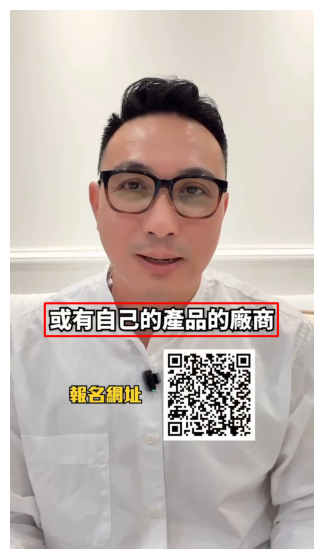

media_id=2066126817504081｜label=0｜第 17.0 秒｜OCR：商品廣告｜命中：['廣告']


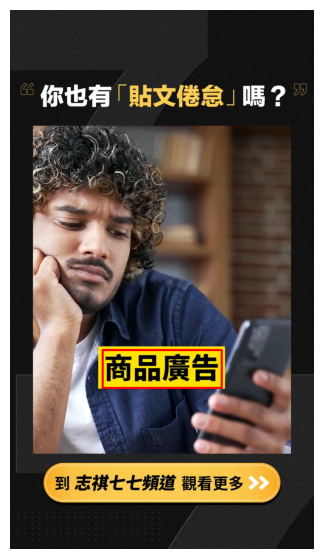

media_id=1977223306553885｜label=1｜第 58.0 秒｜OCR：廣告刊｜命中：['廣告']


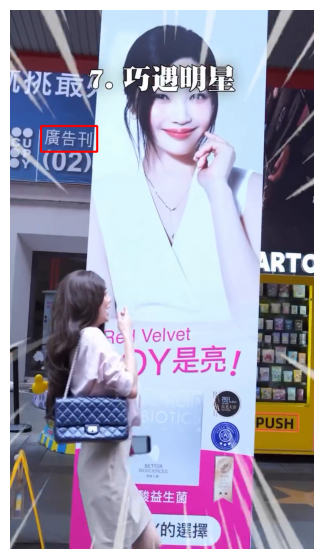

media_id=2436292660163202｜label=1｜第 1.7 秒｜OCR：韓國有-家廠商出售3｜命中：['廠商']


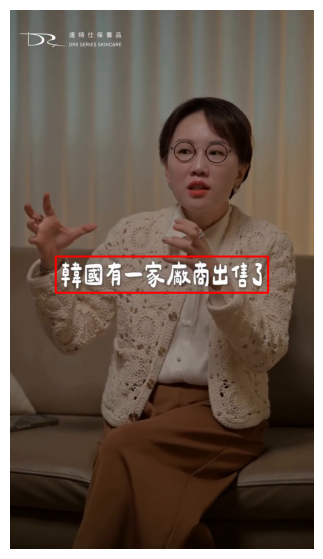

media_id=2436292660163202｜label=1｜第 17.0 秒｜OCR：這家廠商就是交代醫生客戶｜命中：['廠商']


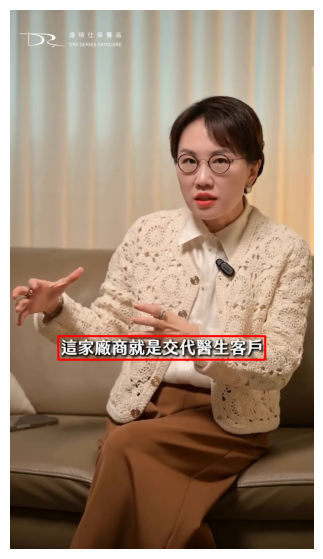

media_id=2436292660163202｜label=1｜第 18.7 秒｜OCR：這家廠商就是交代醫生客戶｜命中：['廠商']


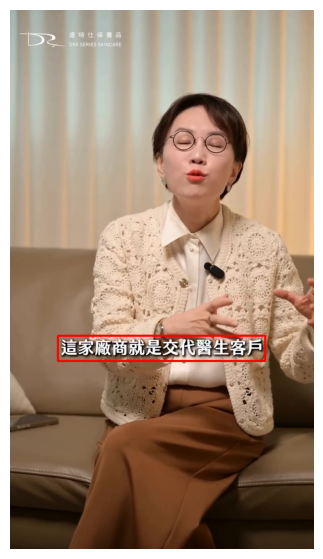

In [75]:
hit_df = (posts.loc[posts["ocr_terms"].str.len() > 0,
                    ["media_id", "username", "stem", "label", "ocr_terms", "video_path"]]
               .reset_index(drop=True))
pd.set_option("display.max_colwidth", None)
display(hit_df.drop(columns="video_path"))

# 逐一顯示命中的影格，紅框 = OCR 找到的那行字
for row in hit_df.itertuples():
    fps  = torch.load(CACHE_DIR / f"{row.media_id}.pt", weights_only=False)["info"]["fps"]
    hits = ocr_hits[row.media_id]
    frames = grab_frames(row.video_path, [h["fid"] for h in hits])
    for h in hits:
        print(f"media_id={row.media_id}｜label={row.label}｜第 {h['fid'] / fps:.1f} 秒｜OCR：{h['text']}｜命中：{h['terms']}")
        img = frames[h["fid"]].copy()
        cv2.polylines(img, [np.array(h["box"], dtype=np.int32)], True, (0, 0, 255), 3)
        plt.figure(figsize=(4, 7))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        plt.show()

## 11.5 人工驗證紀錄

In [ ]:
# 人工檢視結果：is_disclosure = 這行字是否在聲明「本影片」與品牌的業配關係
REVIEW_NOTES = {   # key = media_id，判讀內容來自 11.4 的人工檢視
    "2066126817504081": "知識類影片，談商品廣告造成貼文倦怠",
    "2436292660163202": "主角敘述與廠商相關的經歷，非業配該廠商",
    "1977223306553885": "背景招牌上的「廣告」，路過入鏡",
    "3471424433013354": "「廠商」是他預設的受眾，不是在說自己幫某廠商業配",
}
OCR_REVIEW = hit_df[["media_id", "username", "label", "ocr_terms"]].assign(
    is_disclosure=False,                                   # 4 支皆判定為非揭露
    note=hit_df["media_id"].map(REVIEW_NOTES),
)
assert OCR_REVIEW["note"].notna().all(), "有候選影片還沒寫判讀理由"   # full 資料集時提醒自己補齊

OCR_REVIEW.to_csv(CACHE_DIR.parent / f"{DATA_MODE}_{MODEL_TAG}_ocr_review.csv", index=False)
display(OCR_REVIEW)

verified = set(OCR_REVIEW.loc[OCR_REVIEW["is_disclosure"], "media_id"])
print("OCR 候選：", len(OCR_REVIEW), "支｜經人工確認為揭露：", len(verified), "支")

## 11.6 寫回彙整檔：只遮蔽驗證過的影片

In [78]:
# 只遮蔽人工確認為揭露的影片；pilot 的 verified 是空集合，結果會等於 max_k
X_ver = []
for row in tqdm(posts[ok].itertuples(), total=int(ok.sum()), desc="verified mask"):
    hits = ocr_hits.get(row.media_id, []) if row.media_id in verified else []
    fe = (masked_frame_emb(row, hits) if hits else
          torch.load(CACHE_DIR / f"{row.media_id}.pt", weights_only=False)["frame_emb"].float())
    X_ver.append(fe[np.linspace(0, len(fe) - 1, FIXED_K).round().astype(int)].max(0).values.numpy())
X_ver = np.stack(X_ver)

saved = torch.load(OUT_PT, weights_only=False)
assert saved["media_id"] == posts["media_id"].tolist()
full = torch.zeros(len(posts), X_ver.shape[1])
full[torch.from_numpy(ok)] = torch.from_numpy(X_ver).float()
saved["X_V"]["max_k_masked"] = full
saved["config"]["ocr"] = {"engine": "easyocr ch_tra+en", "conf": OCR_CONF, "frames": f"max_k 的 {FIXED_K} 格",
                          "n_candidates": len(OCR_REVIEW), "n_verified_masked": len(verified),
                          "rule": "關鍵詞篩選候選 → 人工驗證 → 只遮蔽確認為揭露者"}
torch.save(saved, OUT_PT)
print("max_k_masked 已更新（遮蔽", len(verified), "支）")

verified mask:   0%|          | 0/299 [00:00<?, ?it/s]

max_k_masked 已更新（遮蔽 0 支）


## 11.7 Ablation：遮蔽畫面上所有文字（選用）
把 max_k 那 32 格裡**所有** OCR 偵測到的文字都用平均色塗掉，再重新編碼。
目的：區分影片的業配訊號來自「畫面上的文字」（字幕、產品名、價格），還是「畫面本身」（產品、場景、拍攝方式）。
⚠️ 這只是 ablation，不當預設：產品名、折扣碼等是合法的業配線索，正式模型應該保留。
⚠️ 有文字的影格都要重新編碼，CPU 上可能要跑數小時。

In [79]:
def ocr_all_text(row):
    """回傳 max_k 那 32 格裡所有 OCR 偵測到的文字框（不篩選關鍵詞）"""
    c = torch.load(CACHE_DIR / f"{row.media_id}.pt", weights_only=False)
    ts, fps = np.asarray(c["ts"]), c["info"]["fps"]
    sel  = np.linspace(0, len(ts) - 1, FIXED_K).round().astype(int)
    fids = np.round(ts[sel] * fps).astype(int)
    frames = grab_frames(row.video_path, fids)
    return [{"frame_idx": int(j), "fid": int(fid), "box": box}
            for j, fid in zip(sel, fids) if fid in frames
            for box, _, conf in reader.readtext(frames[fid]) if conf >= OCR_CONF]

X_notext, text_frac = [], []
for row in tqdm(posts[ok].itertuples(), total=int(ok.sum()), desc="mask all text"):
    boxes = ocr_all_text(row)
    fe = (masked_frame_emb(row, boxes) if boxes else
          torch.load(CACHE_DIR / f"{row.media_id}.pt", weights_only=False)["frame_emb"].float())
    X_notext.append(fe[np.linspace(0, len(fe) - 1, FIXED_K).round().astype(int)].max(0).values.numpy())
    text_frac.append(len({b["frame_idx"] for b in boxes}) / FIXED_K)
X_notext = np.stack(X_notext)
print("平均每支影片有文字的影格比例：", np.mean(text_frac).round(3))

R[f"max_{K}_notext"] = ap_runs(X_notext)
R[f"text + 長度(非線性) + max_{K}_notext"] = ap_runs(np.c_[X_T, L_nl, X_notext])
print(paired(f"max_{K}", f"max_{K}_notext"))
print(paired(f"text + 長度(非線性) + max_{K}", f"text + 長度(非線性) + max_{K}_notext"))

mask all text:   0%|          | 0/299 [00:00<?, ?it/s]

平均每支影片有文字的影格比例： 0.695
max_32  −  max_32_notext:  Δ = +0.027 ± 0.016｜10 次中贏 9 次
text + 長度(非線性) + max_32  −  text + 長度(非線性) + max_32_notext:  Δ = +0.008 ± 0.005｜10 次中贏 9 次
